## Workflow 3: Orchestrator–Worker Pattern
Orchestrator–Worker mein ek central LLM task ko chhote-chhote subtasks mein divide karta hai aur dynamically workers ko assign karta hai.

"Create a detailed report on Artificial Intelligence."

Ek hi LLM se poori report likhwane ke bajaye hum ye kar sakte hain:
- Orchestrator: Decide karega report mein kaunse sections hone chahiye.
- Worker 1: AI introduction likhega.
- Worker 2: AI applications likhega.
- Worker 3: AI advantages and disadvantages likhega.
- Worker 4: AI future trends likhega.
- Synthesizer: Saare results combine karke final report banayega.
Notice karo: Humein pehle se nahi pata ki kitne workers chahiye. Orchestrator decide karega.

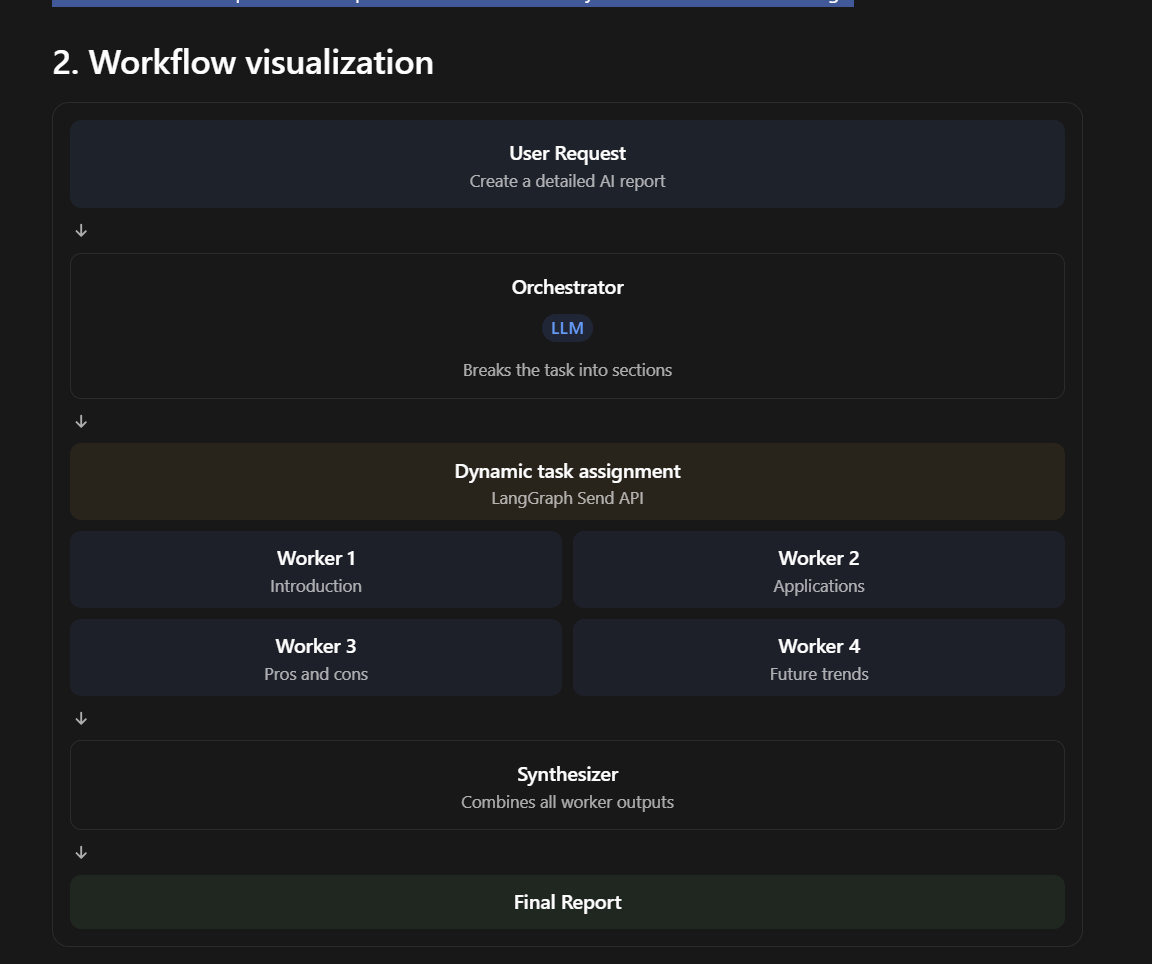





"Orchestrator–Worker is a workflow pattern where an orchestrator breaks a complex task into smaller subtasks, dynamically assigns them to multiple workers, and combines their outputs into a final result. In LangGraph, the Send API enables dynamic worker dispatch."

In [15]:
#Step 1 : Intializing the model
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

response = llm.invoke("Give me a funfact about India")
print(response.content)

Sure! Did you know that India is home to the world’s largest **family‑run business**? The **Tata Group**, founded in 1868, started as a small trading firm and has grown into a multinational conglomerate spanning steel, automobiles, IT services, hospitality, and more—employing over 800,000 people worldwide while still being largely controlled by the Tata family. 🌏🚂✨


## Step 2 : define the State

In [16]:
from typing import TypedDict, Annotated
import operator

class GraphState(TypedDict):
    topic: str
    sections: list[str]
    completed_sections: Annotated[list[str], operator.add]
    final_report: str


# State received by each individual worker
class WorkerState(TypedDict):
    section: str
    completed_sections: Annotated[list[str], operator.add]


#     Notice two things:
# - sections: Orchestrator ke banaye hue tasks.
# - completed_sections: Workers ke results.

## step  — Create the Orchestrator
Orchestrator decide karega ki report mein kaun-kaun se sections hone chahiye.

In [24]:
from pydantic import BaseModel

class Section(BaseModel):
    title: str
    summary: str


class SectionPlan(BaseModel):
    sections: list[Section]

planner = llm.with_structured_output(
    SectionPlan,
    method="json_mode"
)

def orchestrator(state: GraphState):

    plan = planner.invoke(
        f"""
        Create 3 to 5 sections for a detailed report
        about: {state['topic']}.

        Each section must contain:
        - title
        - summary

        Return a JSON object with a sections list.
        """
    )

    return {
        "sections": [
            section.model_dump()
            for section in plan.sections
        ]
    }

#     Example output:
# {    "sections": [        "Introduction to AI",        
#                           "Applications of AI",        "
#                            Advantages and Disadvantages",        
#                            "Future of AI"    ]}



# Remember: Ye example output hai; actual sections LLM decide karega.


## Just testing 
test = planner.invoke(
    """
    Create 4 sections for a detailed report
    about Artificial Intelligence.

    Return JSON with a sections list.
    """
)

print(test)
print(test.sections)

OutputParserException: Failed to parse SectionPlan from completion {"sections": [{"title": "Introduction to Artificial Intelligence", "description": "Overview of AI concepts, history, and its significance in modern technology."}, {"title": "Machine Learning and Deep Learning", "description": "Explanation of core techniques, algorithms, and neural network architectures."}, {"title": "Applications and Impact", "description": "Discussion of AI use cases across industries, societal benefits, and ethical considerations."}, {"title": "Future Trends and Challenges", "description": "Insights into emerging research directions, potential advancements, and obstacles to widespread adoption."}]}. Got: 4 validation errors for SectionPlan
sections.0.summary
  Field required [type=missing, input_value={'title': 'Introduction t... in modern technology.'}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.14/v/missing
sections.1.summary
  Field required [type=missing, inpu

## Step 3 — Create Worker Node

In [25]:
def worker(state: WorkerState):

    section = state["section"]

    response = llm.invoke(
        f"""
        Write a detailed report section.

        Title: {section['title']}
        Description: {section['summary']}

        Topic: Artificial Intelligence.
        """
    )

    return {
        "completed_sections": [
            f"## {section['title']}\n{response.content}"
        ]
    }

## Step 4 — Dynamic Worker Assignment
Yahan LangGraph ka important concept aata hai: Send API.

LangGraph ka Send kya karta hai?

It allows a conditional edge to dynamically dispatch a node with a custom input. Isliye hum same worker node ko different inputs ke saath multiple times execute kar sakte hain.

In [19]:
from langgraph.types import Send


def assign_workers(state: GraphState):

    return [
        Send(
            "worker",
            {"section": section}
        )
        for section in state["sections"]
    ]


# Samjho:

# Agar orchestrator ne 4 sections generate kiye, toh Send 4 worker tasks dispatch karega.

# Har worker ko uska individual section milega.

## Step 5 — Create Synthesizer

In [20]:
def synthesizer(state: GraphState):

    sections = state["completed_sections"]

    response = llm.invoke(
        f"""
        Combine the following sections into
        one well-structured report.

        {sections}

        Maintain a logical flow and avoid repetition.
        """
    )

    return {
        "final_report": response.content
    }

## Step 6 — Create LangGraph

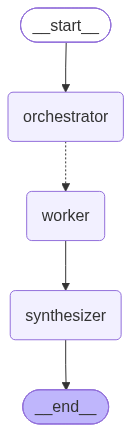

In [21]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(GraphState)

# Add nodes
builder.add_node("orchestrator", orchestrator)
builder.add_node("worker", worker)
builder.add_node("synthesizer", synthesizer)

# Starting edge
builder.add_edge(START, "orchestrator")

# Dynamic worker assignment
builder.add_conditional_edges(
    "orchestrator",
    assign_workers,
    ["worker"]
)

# Workers finish -> synthesizer
builder.add_edge("worker", "synthesizer")

# Finish
builder.add_edge("synthesizer", END)

# Compile
graph = builder.compile()

from IPython.display import display, Markdown, Image

display(Image(graph.get_graph().draw_mermaid_png()))

In [22]:
# Invoke

result = graph.invoke({
    "topic": "Artificial Intelligence",
    "sections": [],
    "completed_sections": [],
    "final_report": ""
})

print(result["final_report"])

BadRequestError: Error code: 400 - {'error': {'message': 'Tool choice is required, but model did not call a tool', 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': '1. Foundations and Evolution of Artificial Intelligence  \n2. Core Technologies and Methodologies  \n3. Applications Across Industries  \n4. Ethical, Legal, and Societal Implications\n\n'}}

## Workflow Pattern 4: Evaluator–Optimizer

"Evaluator–Optimizer is a workflow pattern in which one component generates an output, another evaluates it, and feedback is used to improve the output iteratively until it meets the required quality."

Simple language mein: Ek LLM answer banayega, doosra check karega, aur agar answer satisfactory nahi hai toh pehla usko improve karega.
1. Real-world example
Suppose tum AI Resume Writer bana rahe ho.

User: "Write a professional summary for my resume."

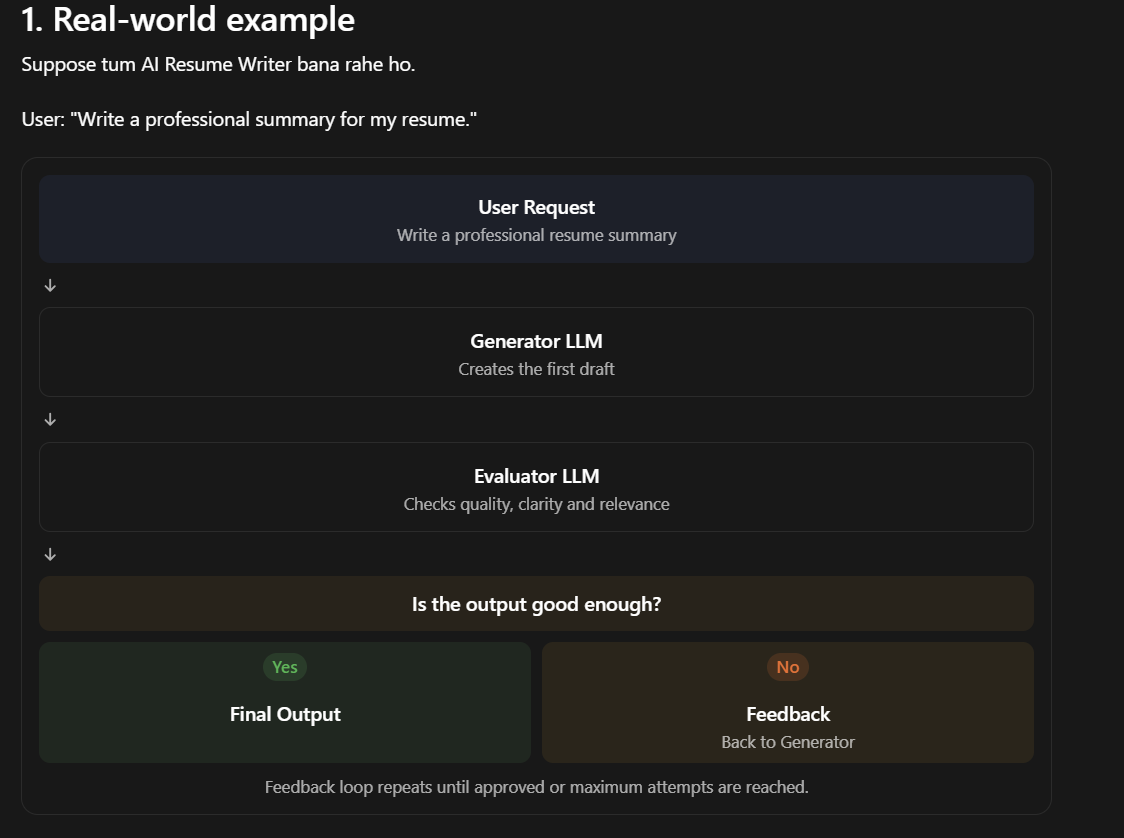


2. Understand with an example
First draft:
I am a hardworking student looking for a job. I know programming.

Evaluator checks it:
- Too generic.
- No technical skills mentioned.
- No specific value or strength.
Feedback:
Mention your technical skills, project experience and problem-solving ability.

Generator improves it:
Computer Science undergraduate with hands-on experience in backend development using Python, FastAPI and Node.js, with experience building practical software projects.

Evaluator checks again. If satisfied, it approves the output.

Yahi Evaluator–Optimizer pattern hai.
3. How is it different from previous workflows?
Workflow	Main purpose
Parallelization	Execute independent tasks together
Routing	Select the appropriate path
Orchestrator–Worker	Break tasks and assign dynamic workers
Evaluator–Optimizer	Generate, evaluate and improve output
ReAct	Decide and execute tools iteratively

4. Important LangGraph concepts used
Is workflow mein tumhe ye concepts milenge:
- Generator node: Creates the initial output or improves it.
- Evaluator node: Evaluates the generated output.
- Conditional edge: Decides whether to finish or repeat.
- State: Stores draft, feedback and iteration count.
- Cycle: Sends execution back to the Generator.
One important thing: evaluator ko stopping condition dena zaroori hai, warna graph unnecessarily loop kar sakta hai. Isliye maximum iteration limit bhi rakhte hain.
5. Where is it useful?
- Resume and cover letter improvement.
- Code generation and code review.
- Content writing and editing.
- SQL query generation and validation.
- Research report improvement.
- Answer quality checking.
